In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

In [3]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.shape

(5110, 12)

In [9]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

In [10]:
print("\nGender Values:")
print(df["gender"].value_counts(dropna=False))

print("\nAge Range:")
print(df["age"].min(), "to", df["age"].max())

print("\nBMI Range:")
print(df["bmi"].min(), "to", df["bmi"].max())

print("\nGlucose Range:")
print(
    df["avg_glucose_level"].min(),
    "to",
    df["avg_glucose_level"].max()
)


Gender Values:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Age Range:
0.08 to 82.0

BMI Range:
10.3 to 97.6

Glucose Range:
55.12 to 271.74


stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


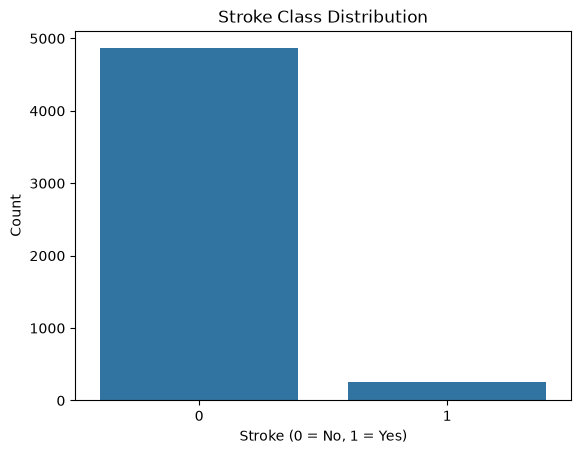

In [11]:
print(df["stroke"].value_counts())
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="stroke")
plt.title("Stroke Class Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


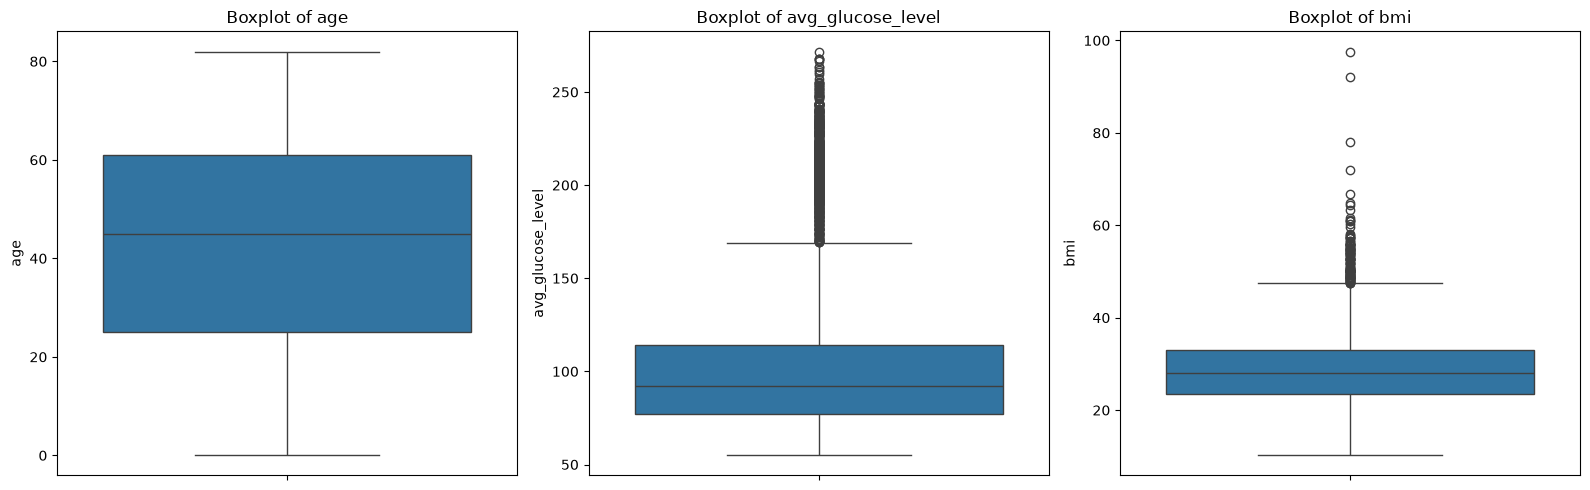

In [12]:

numeric_cols = ["age", "avg_glucose_level", "bmi"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


In [13]:

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", round(Q1, 2))
    print("Q3:", round(Q3, 2))
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Outliers Count:", len(outliers))
    print("Outliers %:", round(len(outliers) / len(df) * 100, 2))



Column: age
Q1: 25.0
Q3: 61.0
Lower Bound: -29.0
Upper Bound: 115.0
Outliers Count: 0
Outliers %: 0.0

Column: avg_glucose_level
Q1: 77.24
Q3: 114.09
Lower Bound: 21.98
Upper Bound: 169.36
Outliers Count: 627
Outliers %: 12.27

Column: bmi
Q1: 23.5
Q3: 33.1
Lower Bound: 9.1
Upper Bound: 47.5
Outliers Count: 110
Outliers %: 2.15


Missing BMI: 201
BMI Mean: 28.893236911794666
BMI Median: 28.1


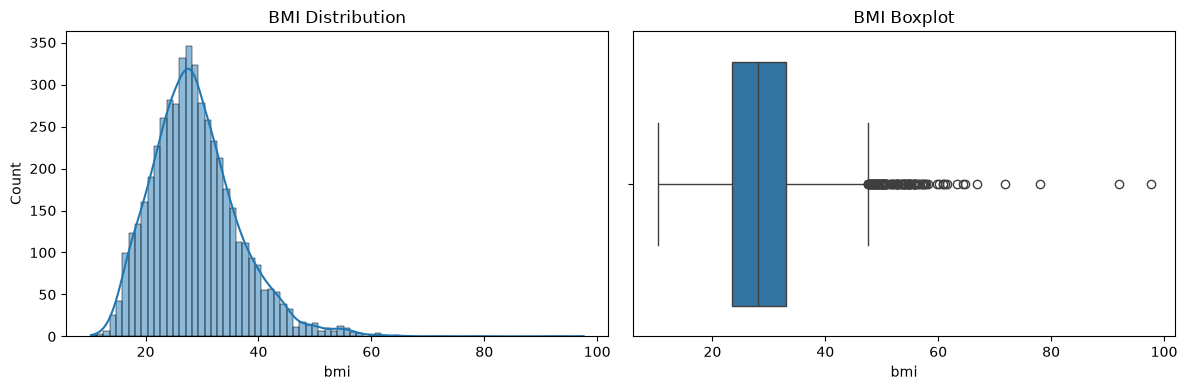

In [14]:

# Check missing BMI values
print("Missing BMI:", df["bmi"].isnull().sum())

# Compare mean and median
print("BMI Mean:", df["bmi"].mean())
print("BMI Median:", df["bmi"].median())

# Visualize BMI distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df,
    x="bmi",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("BMI Distribution")

sns.boxplot(
    data=df,
    x="bmi",
    ax=axes[1]
)
axes[1].set_title("BMI Boxplot")

plt.tight_layout()
plt.show()


In [15]:

df["bmi"] = df["bmi"].fillna(df["bmi"].median())


In [16]:
df.isna().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [17]:

# Handle outliers using IQR Capping
outlier_cols = ["avg_glucose_level", "bmi"]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    print(f"{col}:")
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print()

print("Shape after outlier treatment:", df.shape)


avg_glucose_level:
Lower Bound: 21.98
Upper Bound: 169.36

bmi:
Lower Bound: 10.3
Upper Bound: 46.3

Shape after outlier treatment: (5110, 12)


Missing values: 0


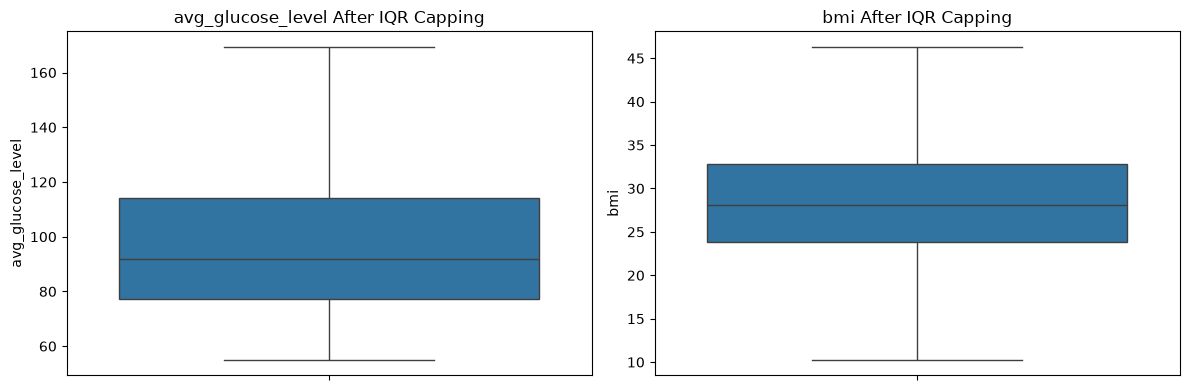

In [18]:

print("Missing values:", df.isnull().sum().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ["avg_glucose_level", "bmi"]):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f"{col} After IQR Capping")

plt.tight_layout()
plt.show()


Missing values: 0


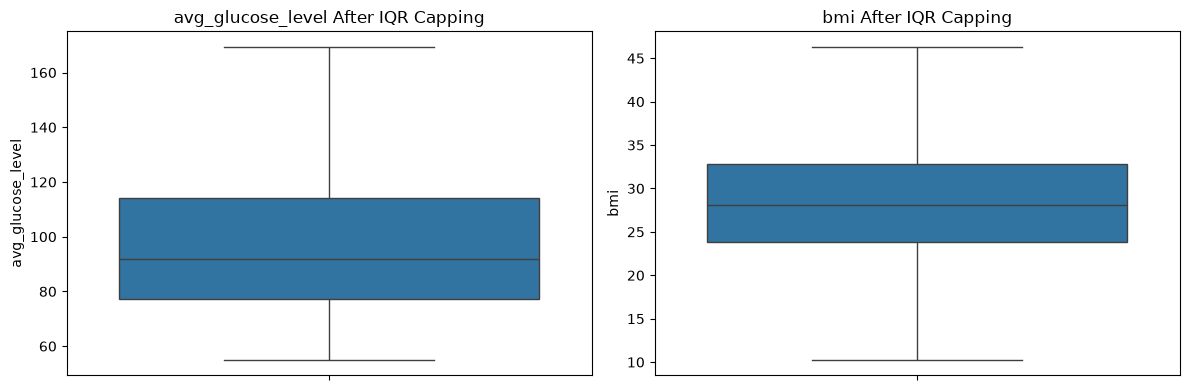

In [19]:

print("Missing values:", df.isnull().sum().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ["avg_glucose_level", "bmi"]):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f"{col} After IQR Capping")

plt.tight_layout()
plt.show()


In [20]:

# Drop ID column
df.drop(columns=["id"], inplace=True)

In [21]:
# Separate target from features
y = df["stroke"]
X = df.drop(columns=["stroke"])

# One-Hot Encoding for categorical features
categorical_cols = X.select_dtypes(include="object").columns.tolist()

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Categorical columns encoded:", categorical_cols)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Categorical columns encoded: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Features shape: (5110, 16)
Target shape: (5110,)


C:\Users\Dell\AppData\Local\Temp\ipykernel_29344\1037208935.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,169.3575,36.6,1,0,1,0,1,0,0,1,1,0,0
1,61.0,0,0,169.3575,28.1,0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.9200,32.5,1,0,1,0,1,0,0,0,0,1,0
3,49.0,0,0,169.3575,34.4,0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,169.3575,24.0,0,0,1,0,0,1,0,0,0,1,0


In [22]:

print("Remaining categorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

print("\nFinal data types:")
print(X.dtypes)


Remaining categorical columns:
[]

Missing values in X: 0
Missing values in y: 0

Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Final data types:
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Male                         int64
gender_Other                        int64
ever_married_Yes                    int64
work_type_Never_worked              int64
work_type_Private                   int64
work_type_Self-employed             int64
work_type_children                  int64
Residence_type_Urban                int64
smoking_status_formerly smoked      int64
smoking_status_never smoked         int64
smoking_status_smokes               int64
dtype: object


In [23]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (4088, 16)
X_test: (1022, 16)
y_train: (4088,)
y_test: (1022,)


# Classification Models

In [24]:
# Imports and evaluation metrics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, balanced_accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    HistGradientBoostingClassifier, VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [25]:
# Scale the features (fit only on training data)
my_scaler = MinMaxScaler()
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

print("X_train =", X_train.shape, " y_train =", y_train.shape)
print("X_test  =", X_test.shape, " y_test  =", y_test.shape)


X_train = (4088, 16)  y_train = (4088,)
X_test  = (1022, 16)  y_test  = (1022,)


In [26]:
# Classification Models
models = {
    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(
        eval_metric="logloss", random_state=1
    ),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}


In [27]:
# Evaluation helper: confusion matrix, classification report, ROC and PR curves
def evaluate_classifier(model, X_train, X_test, y_train, y_test, model_name):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\\n===== {model_name} =====")
    cm = confusion_matrix(y_test, test_pred)
    print("\\nConfusion Matrix:\\n", cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Not Stroke", "Stroke"],
        yticklabels=["Not Stroke", "Stroke"]
    )
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    print("\\nClassification Report:\\n")
    print(classification_report(
        y_test, test_pred,
        target_names=["Not Stroke", "Stroke"],
        zero_division=0
    ))

    # All models in this notebook support predict_proba.
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, label=f"ROC curve (area = {roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {model_name}")
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.figure(figsize=(6, 4))
    plt.plot(recall_vals, precision_vals, label=f"PR AUC = {pr_auc:.2f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - {model_name}")
    plt.legend(loc="lower left")
    plt.show()

    return {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, zero_division=0),
        "Test Precision": precision_score(y_test, test_pred, zero_division=0),
        "Train Recall": recall_score(y_train, train_pred, zero_division=0),
        "Test Recall": recall_score(y_test, test_pred, zero_division=0),
        "Train F1 Score": f1_score(y_train, train_pred, zero_division=0),
        "Test F1 Score": f1_score(y_test, test_pred, zero_division=0),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }


  0%|          | 0/13 [00:00<?, ?it/s]

\n===== Logistic Regression =====
\nConfusion Matrix:\n [[972   0]
 [ 50   0]]


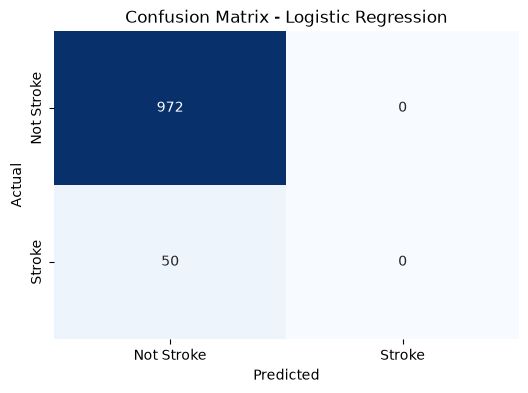

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8424691358024692


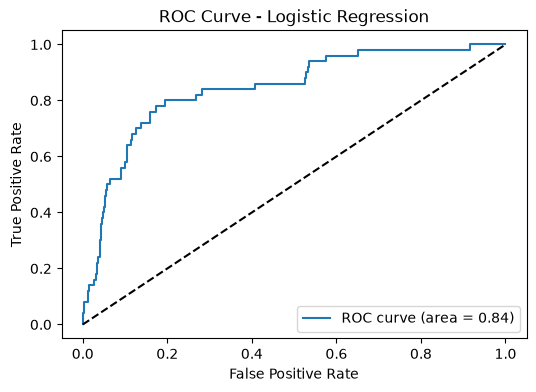

PR AUC: 0.2670904099985243


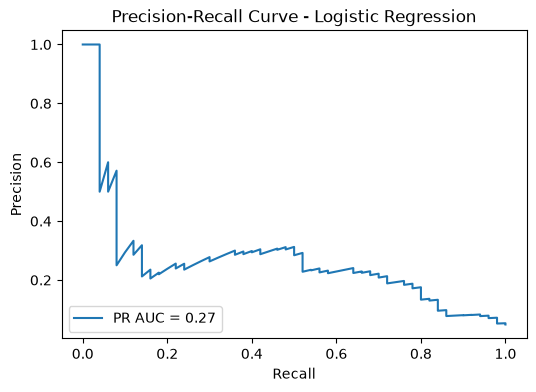

  8%|▊         | 1/13 [00:00<00:05,  2.04it/s]

\n===== KNN =====
\nConfusion Matrix:\n [[970   2]
 [ 47   3]]


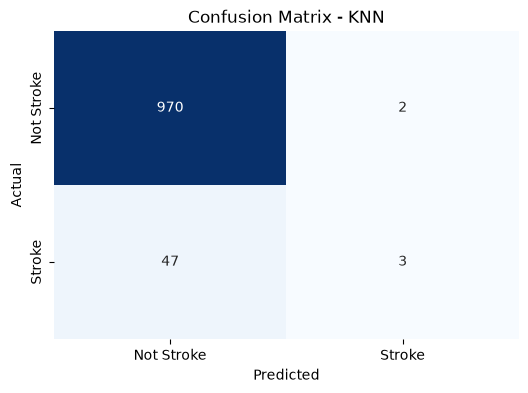

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       972
      Stroke       0.60      0.06      0.11        50

    accuracy                           0.95      1022
   macro avg       0.78      0.53      0.54      1022
weighted avg       0.94      0.95      0.93      1022

ROC-AUC: 0.6084876543209876


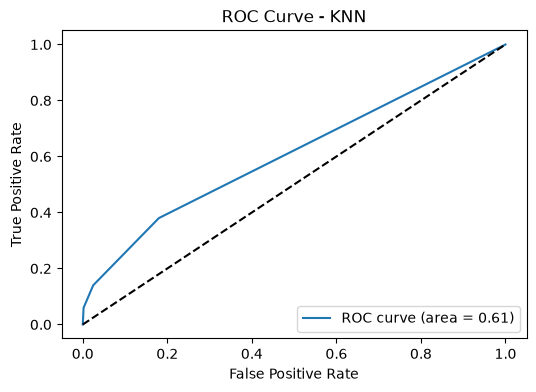

PR AUC: 0.10790235178582003


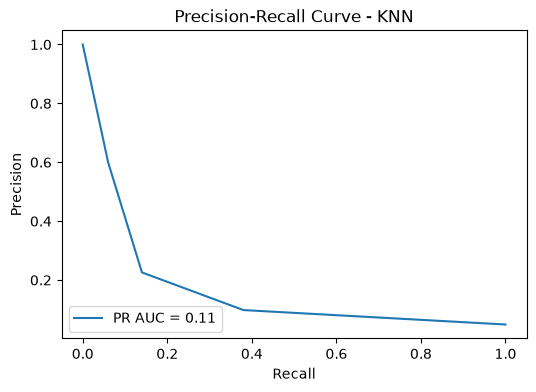

 15%|█▌        | 2/13 [00:01<00:06,  1.80it/s]c:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


\n===== SVC =====
\nConfusion Matrix:\n [[972   0]
 [ 50   0]]


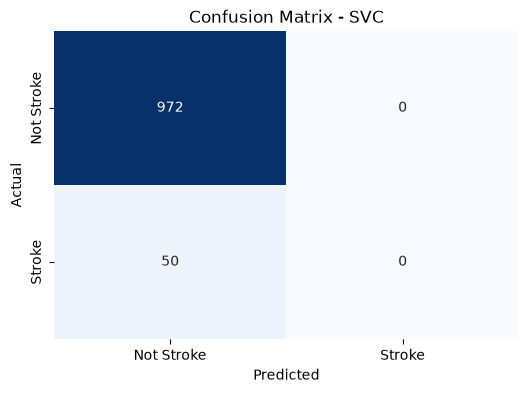

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.6595473251028807


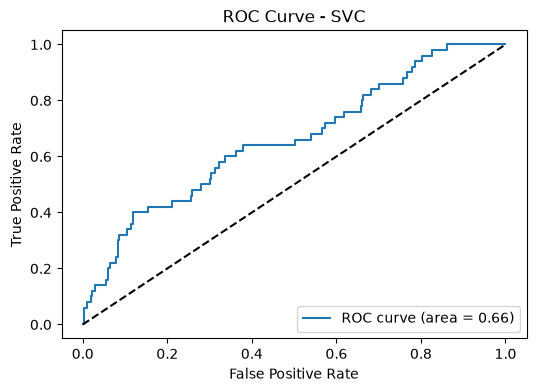

PR AUC: 0.12114726474651881


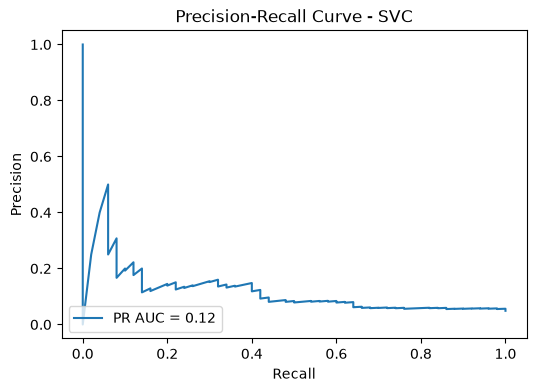

 23%|██▎       | 3/13 [00:03<00:13,  1.30s/it]

\n===== Decision Tree =====
\nConfusion Matrix:\n [[923  49]
 [ 45   5]]


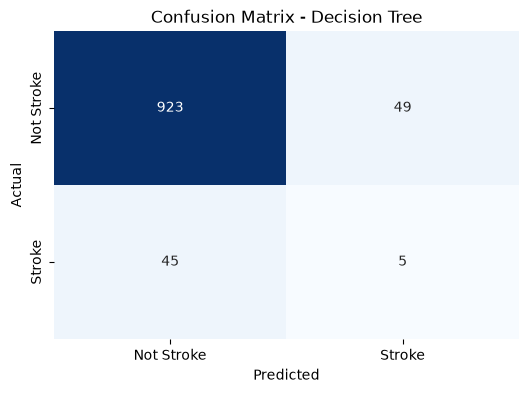

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.95      0.95       972
      Stroke       0.09      0.10      0.10        50

    accuracy                           0.91      1022
   macro avg       0.52      0.52      0.52      1022
weighted avg       0.91      0.91      0.91      1022

ROC-AUC: 0.5247942386831276


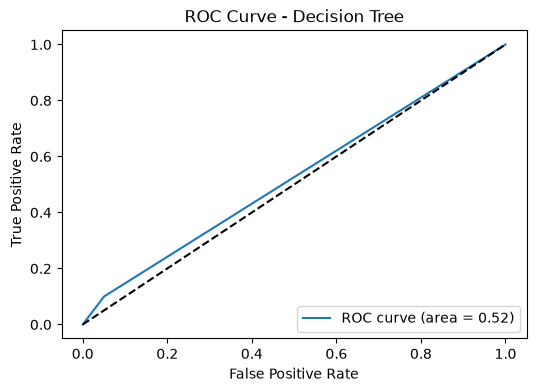

PR AUC: 0.05329057041385808


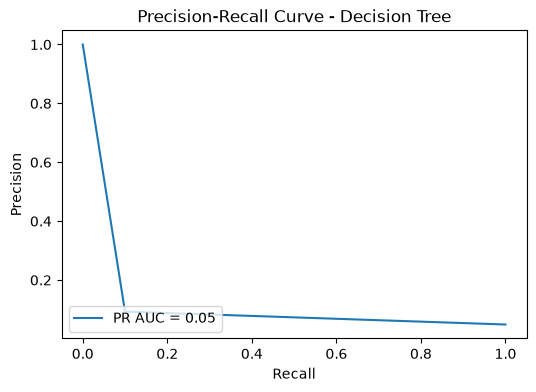

 31%|███       | 4/13 [00:03<00:09,  1.02s/it]

\n===== Naive Bayes =====
\nConfusion Matrix:\n [[145 827]
 [  1  49]]


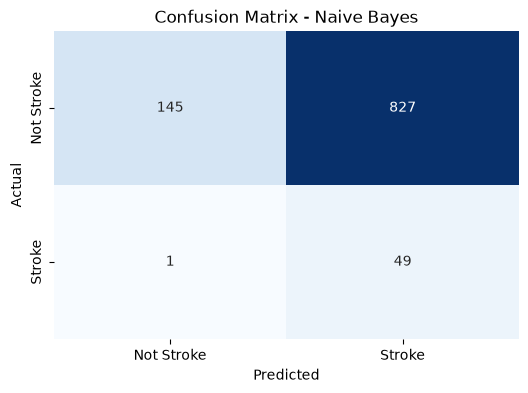

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.99      0.15      0.26       972
      Stroke       0.06      0.98      0.11        50

    accuracy                           0.19      1022
   macro avg       0.52      0.56      0.18      1022
weighted avg       0.95      0.19      0.25      1022

ROC-AUC: 0.7981481481481482


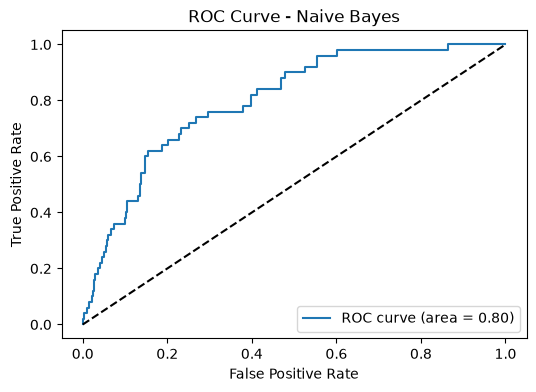

PR AUC: 0.17114604749173395


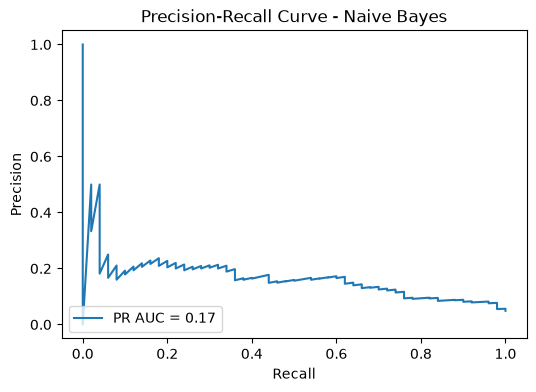

 38%|███▊      | 5/13 [00:04<00:06,  1.23it/s]

\n===== Random Forest =====
\nConfusion Matrix:\n [[971   1]
 [ 48   2]]


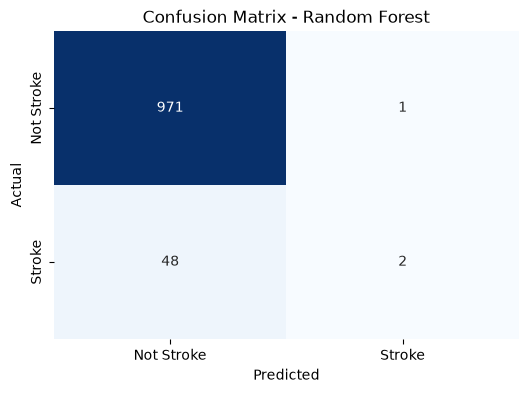

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       972
      Stroke       0.67      0.04      0.08        50

    accuracy                           0.95      1022
   macro avg       0.81      0.52      0.53      1022
weighted avg       0.94      0.95      0.93      1022

ROC-AUC: 0.7873765432098765


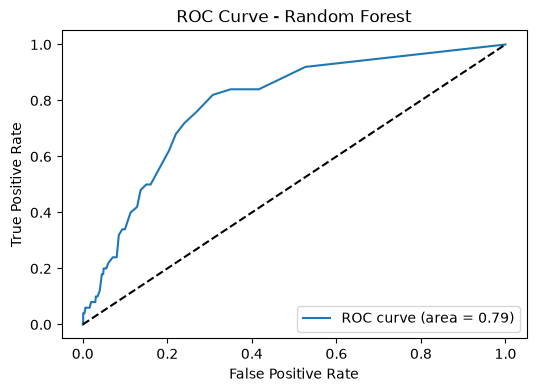

PR AUC: 0.15391204192012936


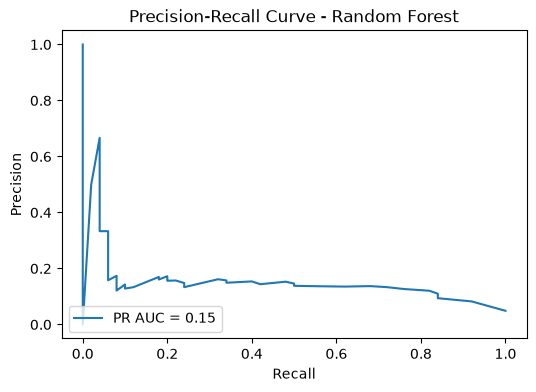

 46%|████▌     | 6/13 [00:05<00:06,  1.16it/s]

\n===== Extra Trees =====
\nConfusion Matrix:\n [[961  11]
 [ 48   2]]


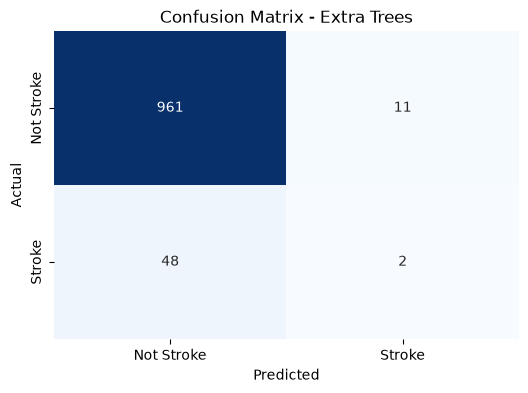

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.15      0.04      0.06        50

    accuracy                           0.94      1022
   macro avg       0.55      0.51      0.52      1022
weighted avg       0.91      0.94      0.93      1022

ROC-AUC: 0.7406275720164608


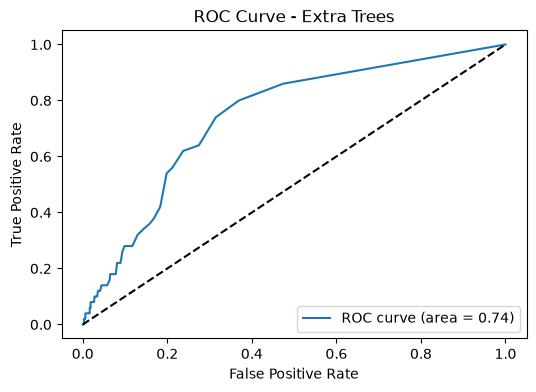

PR AUC: 0.11307401859252583


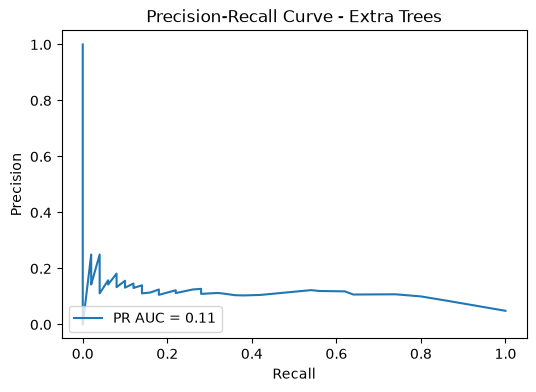

 54%|█████▍    | 7/13 [00:06<00:05,  1.04it/s]

\n===== AdaBoost =====
\nConfusion Matrix:\n [[972   0]
 [ 50   0]]


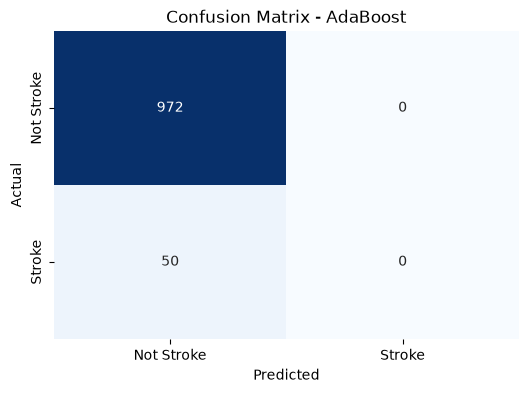

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8287448559670783


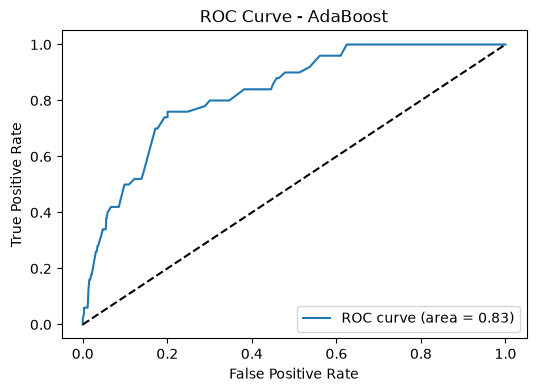

PR AUC: 0.22525228523943236


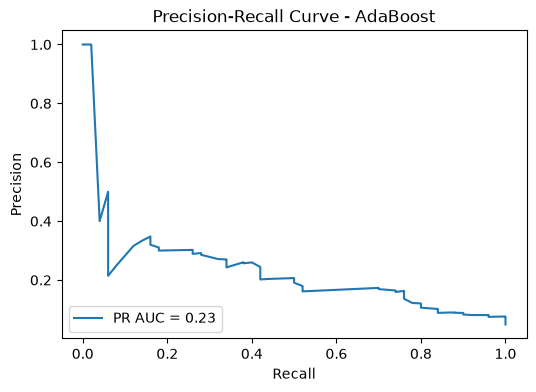

 62%|██████▏   | 8/13 [00:07<00:04,  1.14it/s]

\n===== Gradient Boosting =====
\nConfusion Matrix:\n [[970   2]
 [ 49   1]]


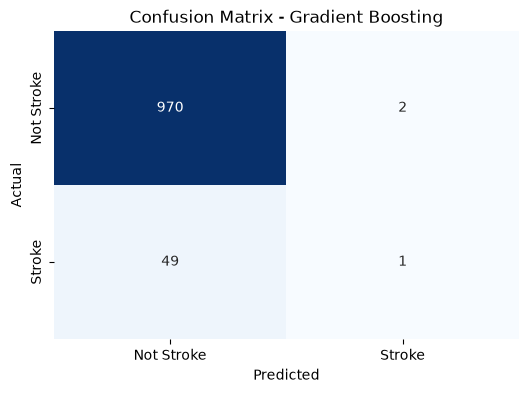

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.33      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.64      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8348456790123457


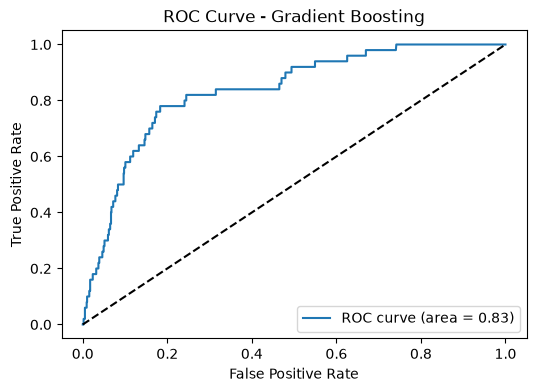

PR AUC: 0.20772273451408738


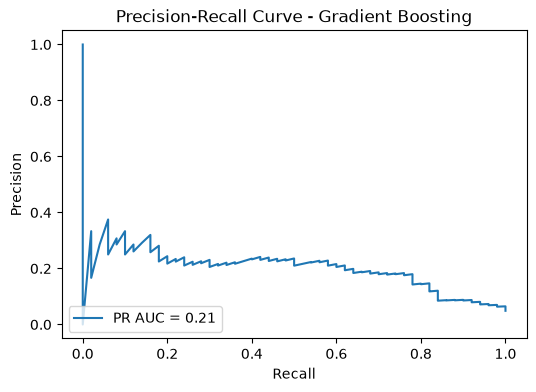

 69%|██████▉   | 9/13 [00:08<00:03,  1.06it/s]

\n===== Hist Gradient Boosting =====
\nConfusion Matrix:\n [[962  10]
 [ 48   2]]


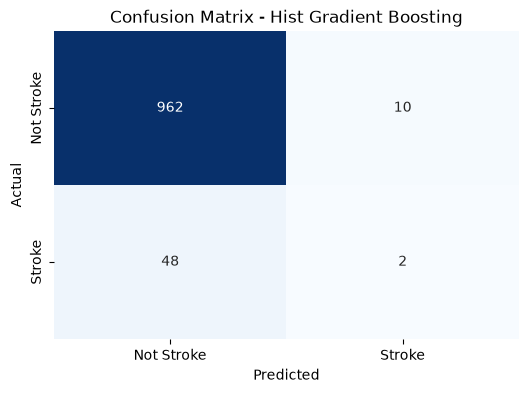

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.17      0.04      0.06        50

    accuracy                           0.94      1022
   macro avg       0.56      0.51      0.52      1022
weighted avg       0.91      0.94      0.93      1022

ROC-AUC: 0.8287654320987654


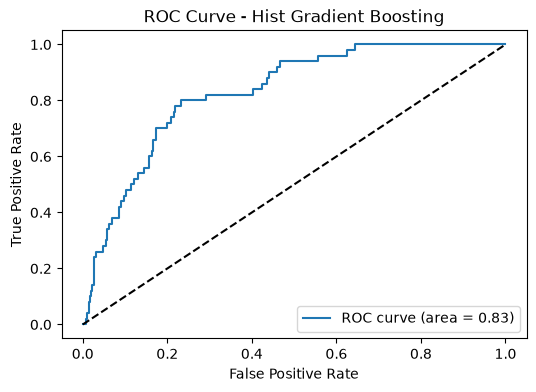

PR AUC: 0.1805792926057136


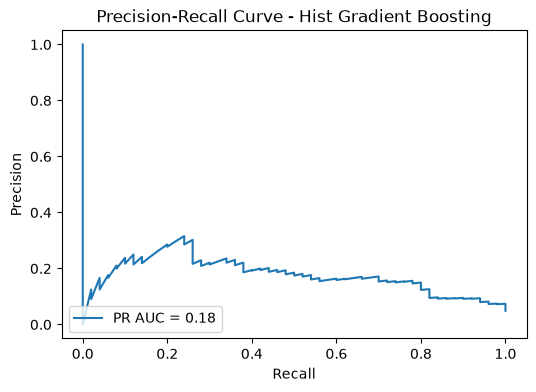

 77%|███████▋  | 10/13 [00:09<00:02,  1.02it/s]

\n===== XGBoost =====
\nConfusion Matrix:\n [[963   9]
 [ 46   4]]


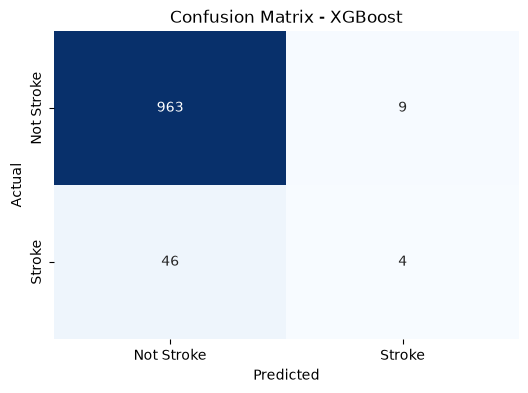

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.31      0.08      0.13        50

    accuracy                           0.95      1022
   macro avg       0.63      0.54      0.55      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.799074074074074


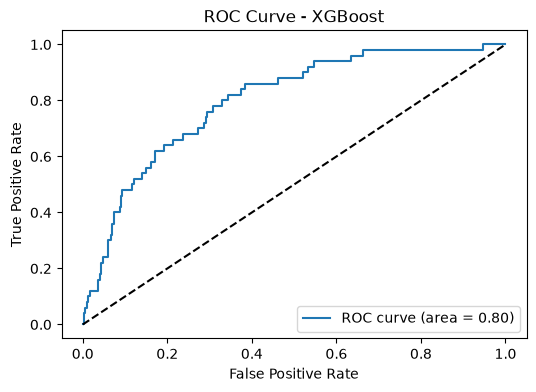

PR AUC: 0.17121393278913366


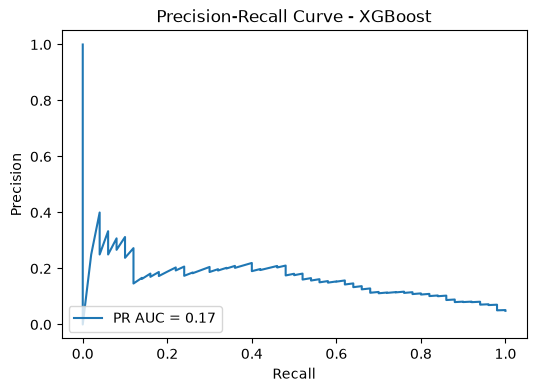

 85%|████████▍ | 11/13 [00:10<00:01,  1.02it/s]

\n===== CatBoost =====
\nConfusion Matrix:\n [[968   4]
 [ 46   4]]


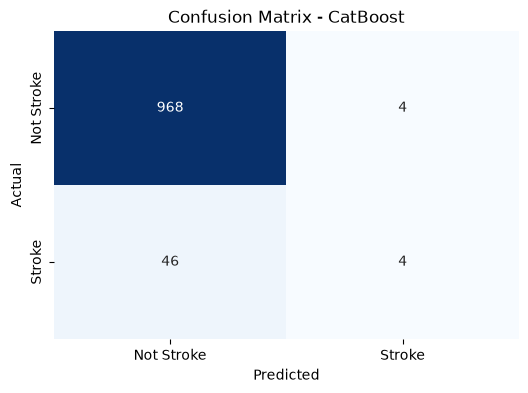

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.50      0.08      0.14        50

    accuracy                           0.95      1022
   macro avg       0.73      0.54      0.56      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.8248148148148148


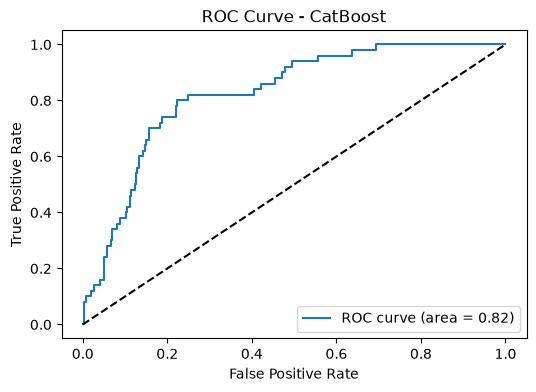

PR AUC: 0.18587967999274432


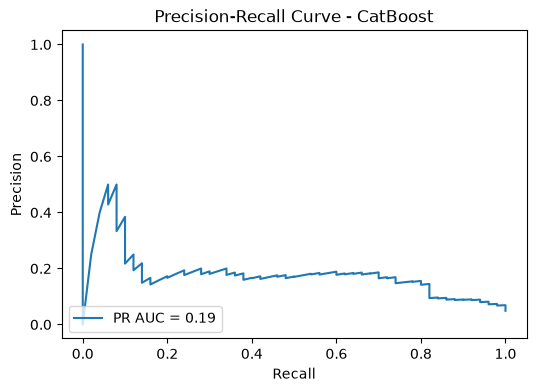

 92%|█████████▏| 12/13 [00:15<00:02,  2.13s/it]

[LightGBM] [Info] Number of positive: 199, number of negative: 3889
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000197 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 629
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048679 -> initscore=-2.972603
[LightGBM] [Info] Start training from score -2.972603
\n===== LightGBM =====
\nConfusion Matrix:\n [[964   8]
 [ 47   3]]


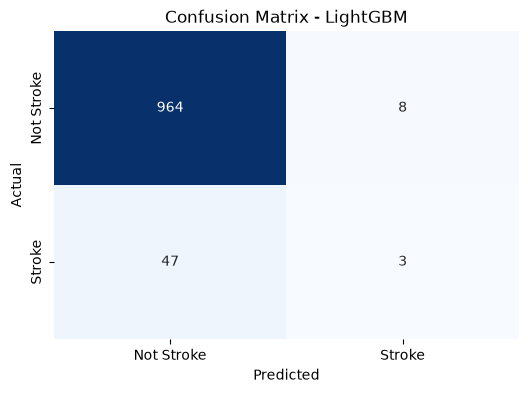

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.27      0.06      0.10        50

    accuracy                           0.95      1022
   macro avg       0.61      0.53      0.54      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8272222222222222


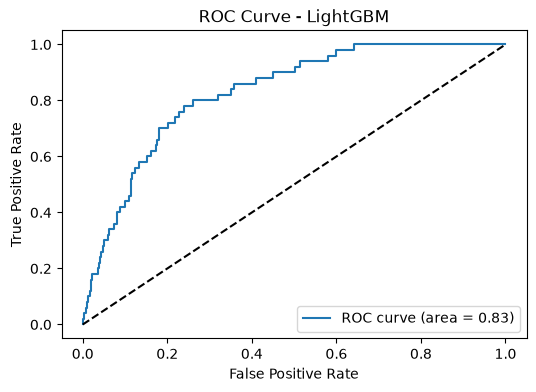

PR AUC: 0.20378851089602693


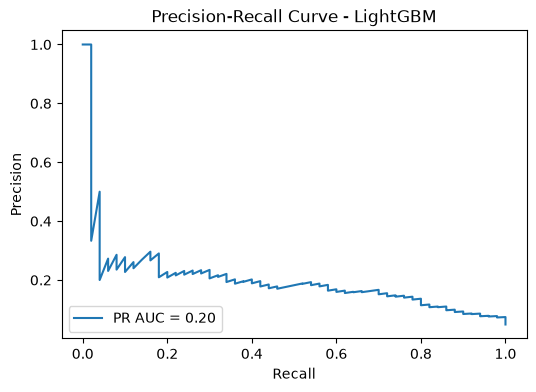

100%|██████████| 13/13 [00:15<00:00,  1.21s/it]


In [28]:
# Train and evaluate all classification models
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)
    results[name] = evaluate_classifier(
        model, X_train, X_test, y_train, y_test, name
    )


# Voting Classification

\n===== Voting Classifier =====
\nConfusion Matrix:\n [[960  12]
 [ 46   4]]


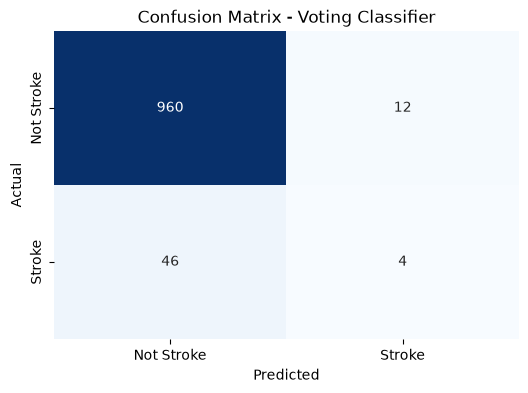

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.25      0.08      0.12        50

    accuracy                           0.94      1022
   macro avg       0.60      0.53      0.55      1022
weighted avg       0.92      0.94      0.93      1022

ROC-AUC: 0.8273251028806584


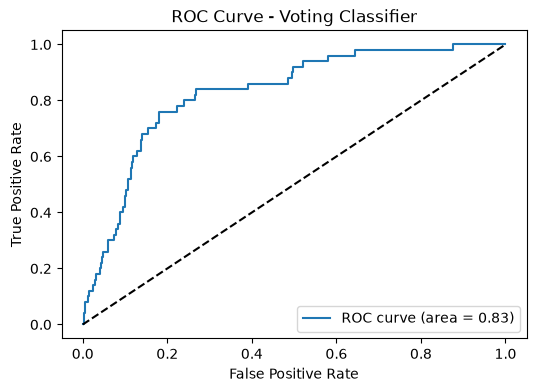

PR AUC: 0.19057465326763756


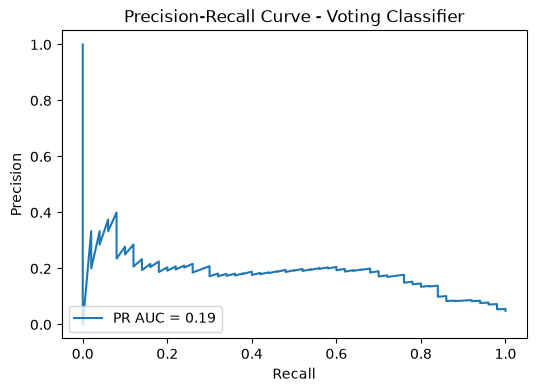

In [29]:
# Soft Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"])
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)
results["Voting Classifier"] = evaluate_classifier(
    voting_model, X_train, X_test, y_train, y_test, "Voting Classifier"
)


# Stacking Classifier

\n===== Stacking Classifier =====
\nConfusion Matrix:\n [[962  10]
 [ 50   0]]


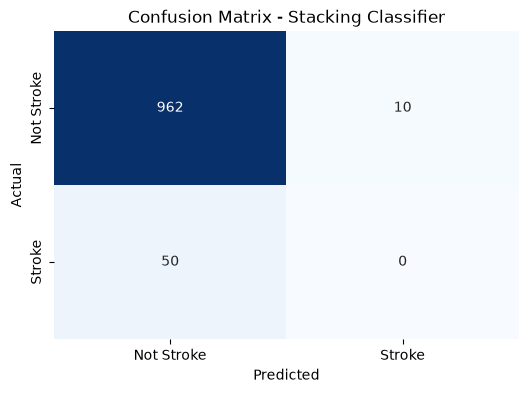

\nClassification Report:\n
              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.94      1022
   macro avg       0.48      0.49      0.48      1022
weighted avg       0.90      0.94      0.92      1022

ROC-AUC: 0.7631378600823046


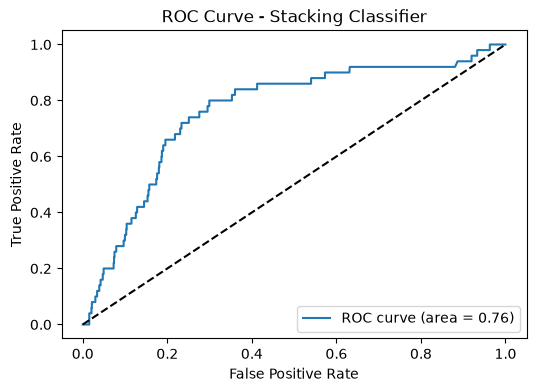

PR AUC: 0.12672245306003324


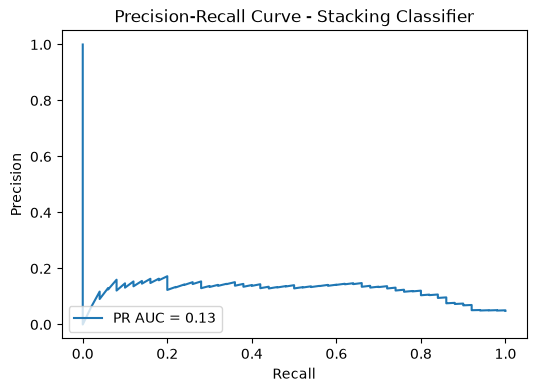

In [30]:
# Stacking Classifier
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"])
    ],
    final_estimator=XGBClassifier(
        n_estimators=100, eval_metric="logloss", random_state=1
    ),
    stack_method="predict_proba",
    n_jobs=-1
)

stack_auto.fit(X_train, y_train)
results["Stacking Classifier"] = evaluate_classifier(
    stack_auto, X_train, X_test, y_train, y_test, "Stacking Classifier"
)


# Model Comparison

In [31]:
# Sort models by Test F1 Score
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(
    by="Test F1 Score", ascending=False
)


## Accuracy Comparison Table

In [33]:
# Accuracy comparison for all trained classification models
accuracy_table = results_df[["Train Accuracy", "Test Accuracy"]].copy()

accuracy_table = accuracy_table.sort_values(
    by="Test Accuracy",
    ascending=False
)

# Display accuracy as percentages
accuracy_table = (accuracy_table * 100).round(2)

accuracy_table = accuracy_table.rename(columns={
    "Train Accuracy": "Train Accuracy (%)",
    "Test Accuracy": "Test Accuracy (%)"
})

display(accuracy_table)


,Train Accuracy (%),Test Accuracy (%)
KNN,95.25,95.21
Random Forest,100.00,95.21
CatBoost,97.31,95.11
Logistic Regression,95.13,95.11
SVC,95.13,95.11
AdaBoost,95.13,95.11
Gradient Boosting,95.72,95.01
XGBoost,99.56,94.62
LightGBM,99.12,94.62
Voting Classifier,99.95,94.32


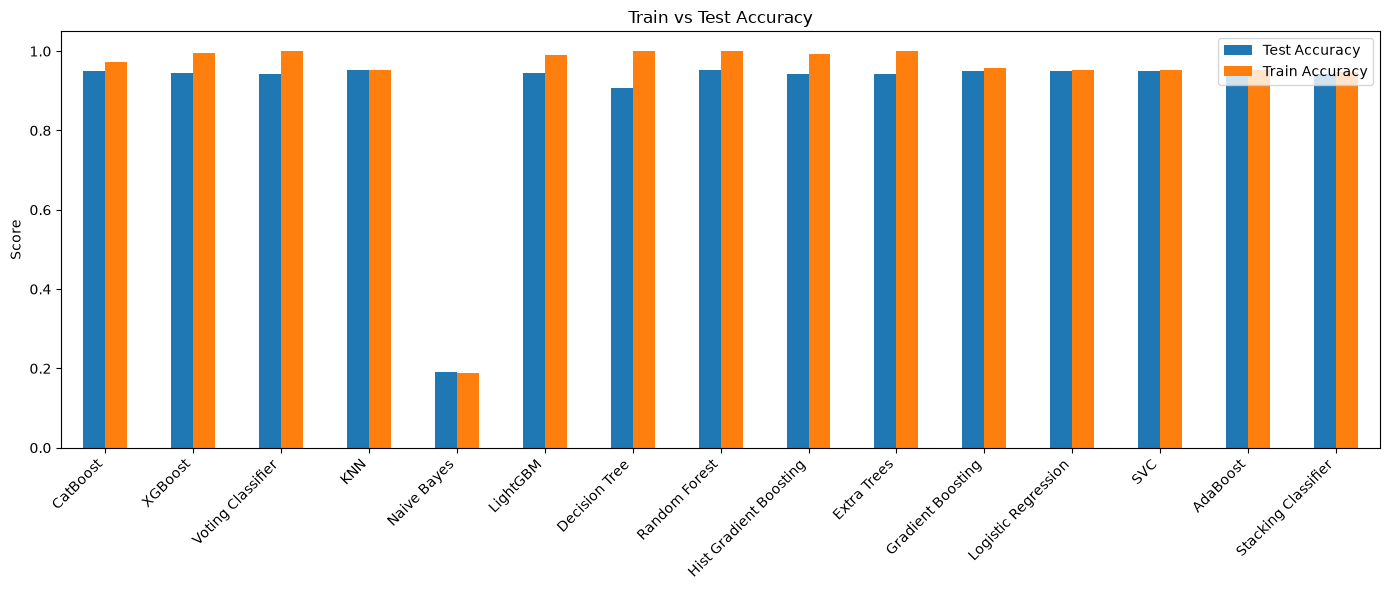

In [34]:
# Compare Train and Test Accuracy
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(14, 6))
plt.title("Train vs Test Accuracy")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


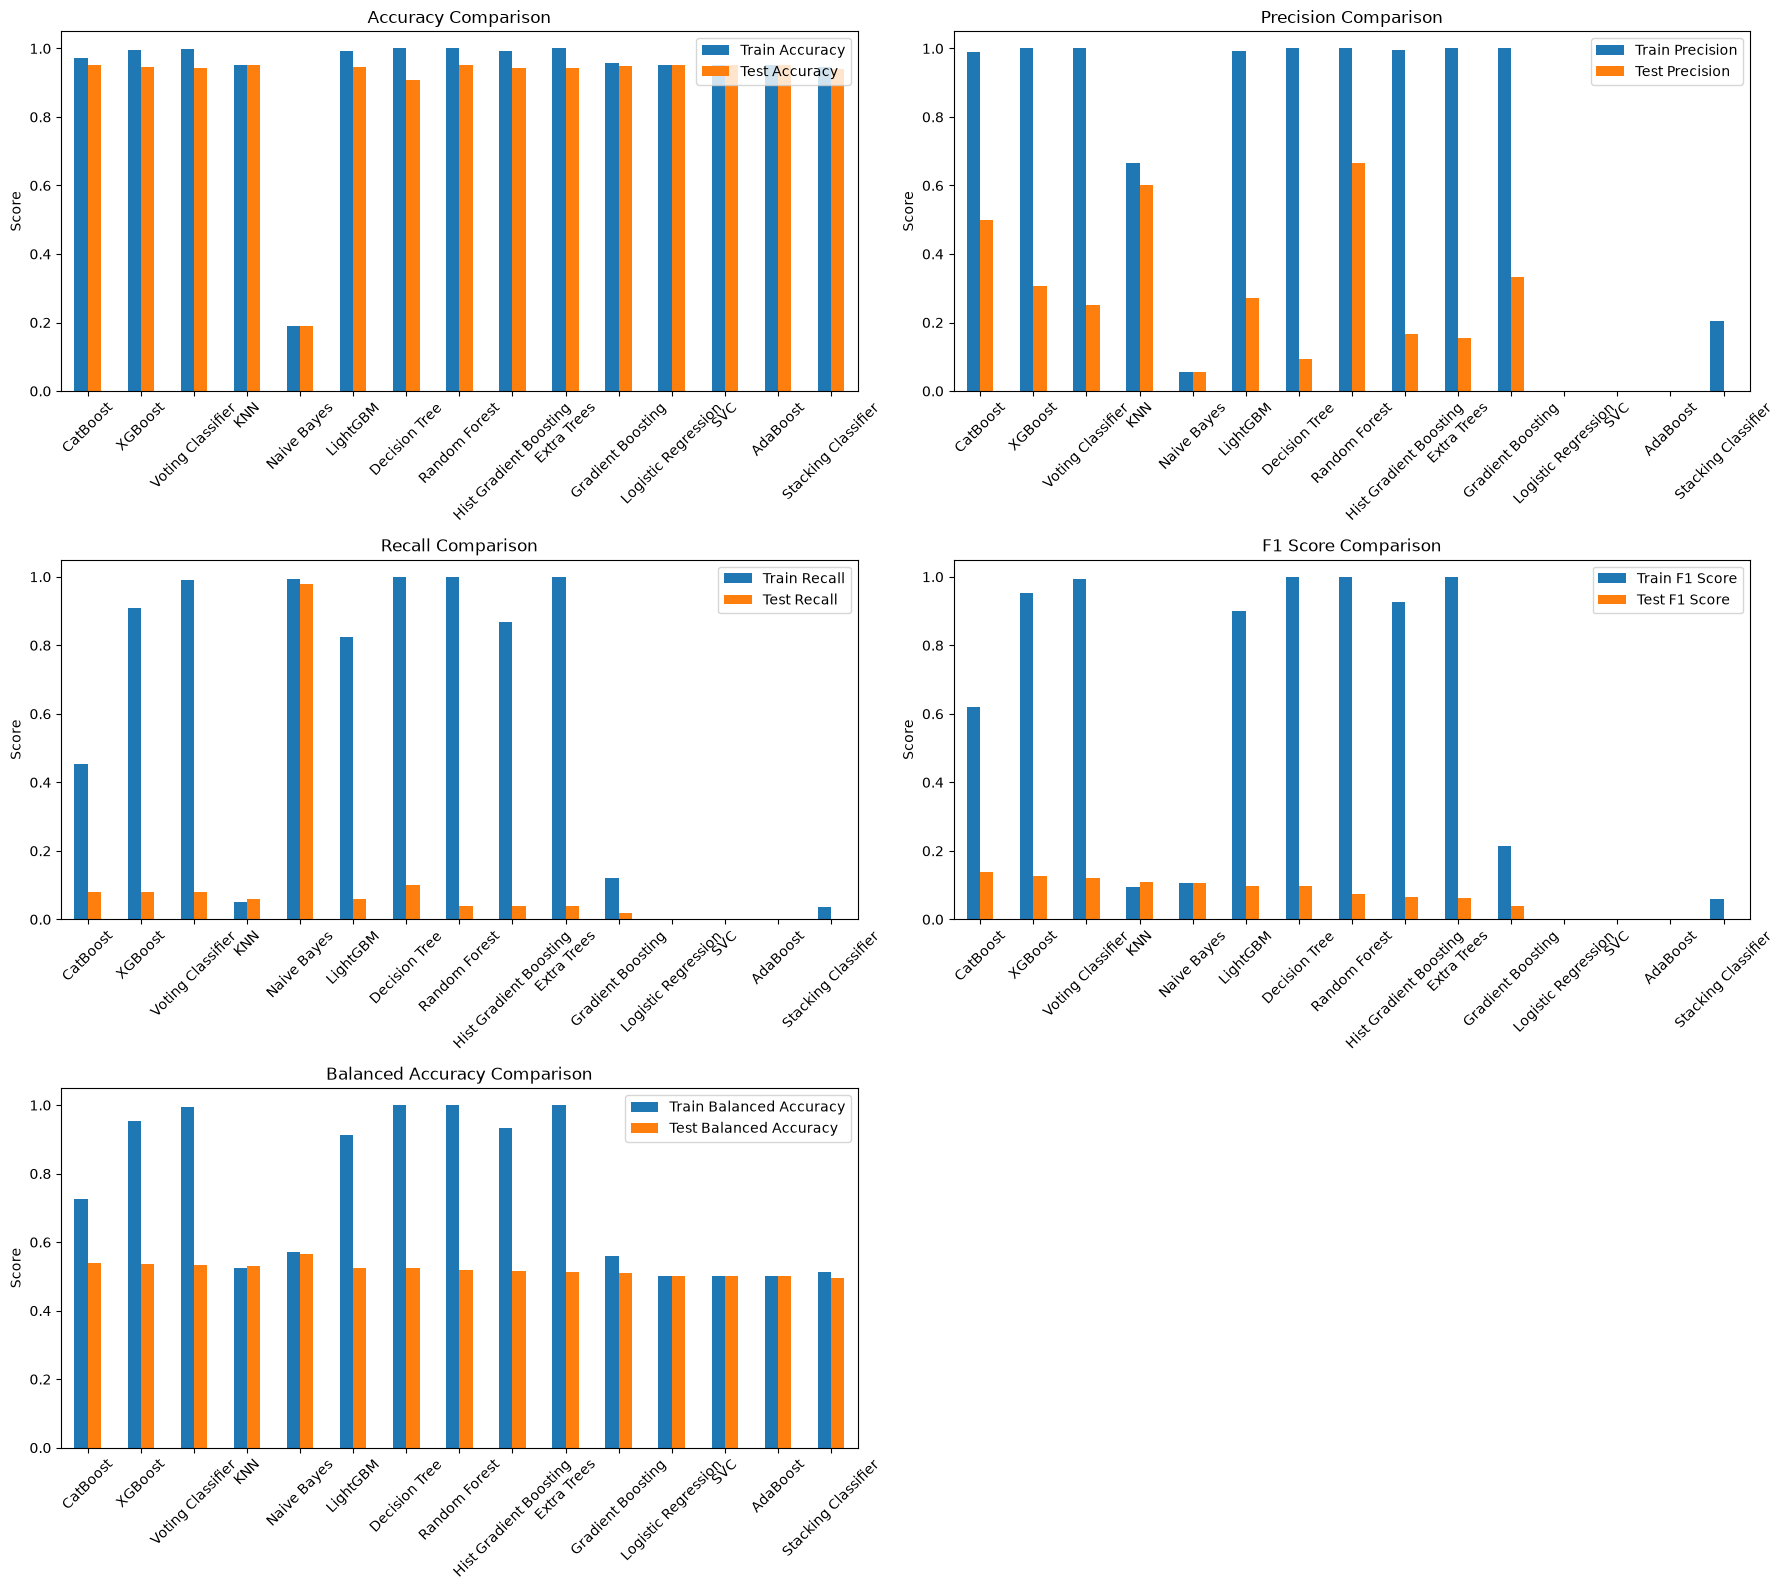

In [35]:
# Compare the main classification metrics
cols = [
    ["Train Accuracy", "Test Accuracy"],
    ["Train Precision", "Test Precision"],
    ["Train Recall", "Test Recall"],
    ["Train F1 Score", "Test F1 Score"],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

fig, axes = plt.subplots(3, 2, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(cols):
    results_df[col].plot.bar(ax=axes[i])
    axes[i].set_title(col[0].replace("Train ", "") + " Comparison")
    axes[i].set_ylabel("Score")
    axes[i].tick_params(axis="x", rotation=45)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


In [36]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.973092,0.951076,0.989011,0.500000,0.452261,0.08,0.620690,0.137931,0.726002,0.537942,0.824815,0.185880
XGBoost,0.995597,0.946184,1.000000,0.307692,0.909548,0.08,0.952632,0.126984,0.954774,0.535370,0.799074,0.171214
Voting Classifier,0.999511,0.943249,1.000000,0.250000,0.989950,0.08,0.994949,0.121212,0.994975,0.533827,0.827325,0.190575
KNN,0.952544,0.952055,0.666667,0.600000,0.050251,0.06,0.093458,0.109091,0.524483,0.528971,0.608488,0.107902
Naive Bayes,0.189579,0.189824,0.056410,0.055936,0.994975,0.98,0.106767,0.105832,0.571671,0.564588,0.798148,0.171146
LightGBM,0.991194,0.946184,0.993939,0.272727,0.824121,0.06,0.901099,0.098361,0.911932,0.525885,0.827222,0.203789
Decision Tree,1.000000,0.908023,1.000000,0.092593,1.000000,0.10,1.000000,0.096154,1.000000,0.524794,0.524794,0.053291
Random Forest,1.000000,0.952055,1.000000,0.666667,1.000000,0.04,1.000000,0.075472,1.000000,0.519486,0.787377,0.153912
Hist Gradient Boosting,0.993395,0.943249,0.994253,0.166667,0.869347,0.04,0.927614,0.064516,0.934545,0.514856,0.828765,0.180579
Extra Trees,1.000000,0.942270,1.000000,0.153846,1.000000,0.04,1.000000,0.063492,1.000000,0.514342,0.740628,0.113074
